In [1]:
from pathlib import Path
import tarfile
import shutil
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

### Configuración general

In [2]:
BASE_DIR = Path.cwd()
TAR_PATH = BASE_DIR / "final_sequential_results_2026_06_04.tar.gz"

WORK_DIR = BASE_DIR / "final_results_extracted" # Carpeta temporal 
OUTPUT_DIR = BASE_DIR / "final_analysis_outputs" # Carpeta para tablas y figuras
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALGORITHM_LABELS = {
    "random": "Random",
    "nsga3": "NSGA-III",
    "grasp": "GRASP",
    "hh_lap_v0": "HH-LAP-SIPA-Lite",
    "hh_lap_v1": "HH-LAP-SIPA-Intensive",
}

ALGORITHM_ORDER = [
    "random",
    "nsga3",
    "grasp",
    "hh_lap_v0",
    "hh_lap_v1",
]

LABEL_ORDER = [ALGORITHM_LABELS[a] for a in ALGORITHM_ORDER]

print("BASE_DIR:", BASE_DIR)
print("TAR_PATH:", TAR_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

BASE_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results
TAR_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_sequential_results_2026_06_04.tar.gz
OUTPUT_DIR: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_analysis_outputs


In [3]:
# Extracción del .tar

def safe_extract_tar(tar_path: Path, extract_to: Path) -> None:
    """
    Extrae un .tar.gz evitando path traversal.
    """
    extract_to = extract_to.resolve()

    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar.getmembers():
            target_path = (extract_to / member.name).resolve()
            if not str(target_path).startswith(str(extract_to)):
                raise RuntimeError(f"Ruta insegura dentro del tar: {member.name}")

        tar.extractall(extract_to)


# Limpiar extracción anterior, si existe
if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

WORK_DIR.mkdir(parents=True, exist_ok=True)

safe_extract_tar(TAR_PATH, WORK_DIR)

print("Resultados extraídos en:", WORK_DIR)

Resultados extraídos en: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted


### Cargar CSVs

In [4]:
candidates = list(WORK_DIR.glob("**/final_sequential"))

if not candidates:
    raise FileNotFoundError("No se ha encontrado la carpeta final_sequential dentro del .tar.gz")

ROOT = candidates[0]

print("ROOT:", ROOT)

HV_RUN_PATH = ROOT / "hypervolume" / "hypervolume_by_run.csv"
HV_SUMMARY_PATH = ROOT / "hypervolume" / "hypervolume_summary.csv"
STATS_PATH = ROOT / "statistics" / "statistics_all.csv"

print("HV_RUN_PATH:", HV_RUN_PATH)
print("HV_SUMMARY_PATH:", HV_SUMMARY_PATH)
print("STATS_PATH:", STATS_PATH)

ROOT: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential
HV_RUN_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\hypervolume\hypervolume_by_run.csv
HV_SUMMARY_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\hypervolume\hypervolume_summary.csv
STATS_PATH: c:\Code\VRAIN-practicas\Code\Teachers+Centers\results\final_results_extracted\results\final_sequential\statistics\statistics_all.csv


In [5]:
hv_run = pd.read_csv(HV_RUN_PATH)
hv_summary = pd.read_csv(HV_SUMMARY_PATH)
stats_all = pd.read_csv(STATS_PATH)

print("hypervolume_by_run:", hv_run.shape)
print("hypervolume_summary:", hv_summary.shape)
print("statistics_all:", stats_all.shape)

display(hv_run.head())
display(hv_summary.head())
display(stats_all.head())

hypervolume_by_run: (3000, 14)
hypervolume_summary: (100, 8)
statistics_all: (3000, 20)


,algorithm,instance,n_students,run_id,pareto_points,hypervolume,min_tau,min_eta,min_lbar,min_sigma,max_tau,max_eta,max_lbar,max_sigma
0,grasp,problem_instance_ext_1000_0.txt,1000,0,2,0.009976,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
1,grasp,problem_instance_ext_1000_0.txt,1000,1,1,0.008290,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
2,grasp,problem_instance_ext_1000_0.txt,1000,2,2,0.007927,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
3,grasp,problem_instance_ext_1000_0.txt,1000,3,2,0.008352,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954
4,grasp,problem_instance_ext_1000_0.txt,1000,4,2,0.008174,153.231576,35.4857,1.608096,0.001806,790.145992,594.6044,2.40544,0.591954


,algorithm,instance,n_students,n_runs,mean_hv,std_hv,min_hv,max_hv
0,grasp,problem_instance_ext_1000_0.txt,1000,30,0.008517,0.000604,0.007319,0.009976
1,grasp,problem_instance_ext_1000_1.txt,1000,30,0.012071,0.001572,0.008772,0.014948
2,grasp,problem_instance_ext_1000_2.txt,1000,30,0.010060,0.001458,0.007448,0.012972
3,grasp,problem_instance_ext_1000_3.txt,1000,30,0.011545,0.001087,0.009093,0.014387
4,grasp,problem_instance_ext_200_0.txt,200,30,0.346370,0.069761,0.019356,0.420340


,timestamp,algorithm,instance,n_students,run_id,seed,time_limit_seconds,elapsed_seconds,status,error_message,pareto_size,generated,feasible,failures,inserted_into_pareto,iterations,generations,population_size,offspring_size,reference_points
0,2026-05-18 17:32:45,random,problem_instance_ext_1000_0.txt,1000,0,622263440,600,600.154644,ok,NaN,76,2112.0,2112.0,0.0,163,2112.0,NaN,NaN,NaN,NaN
1,2026-05-18 17:42:45,random,problem_instance_ext_1000_0.txt,1000,1,622263441,600,600.170744,ok,NaN,76,2123.0,2123.0,0.0,162,2123.0,NaN,NaN,NaN,NaN
2,2026-05-18 17:52:45,random,problem_instance_ext_1000_0.txt,1000,2,622263442,600,600.027184,ok,NaN,76,2089.0,2089.0,0.0,161,2089.0,NaN,NaN,NaN,NaN
3,2026-05-18 18:02:46,random,problem_instance_ext_1000_0.txt,1000,3,622263443,600,600.031791,ok,NaN,73,2017.0,2017.0,0.0,157,2017.0,NaN,NaN,NaN,NaN
4,2026-05-18 18:12:46,random,problem_instance_ext_1000_0.txt,1000,4,622263444,600,600.258343,ok,NaN,73,2018.0,2018.0,0.0,156,2018.0,NaN,NaN,NaN,NaN


### Limpieza

In [6]:
# ============================================================
# LIMPIEZA BÁSICA
# ============================================================

def normalize_instance_name(x):
    """
    Normaliza el nombre de instancia.
    """
    name = Path(str(x)).name
    name = name.replace(".txt", "")
    name = name.replace(".csv", "")
    return name


for df in [hv_run, hv_summary, stats_all]:
    df["instance_clean"] = df["instance"].apply(normalize_instance_name)
    df["algorithm_label"] = df["algorithm"].map(ALGORITHM_LABELS)

    df["algorithm"] = pd.Categorical(
        df["algorithm"],
        categories=ALGORITHM_ORDER,
        ordered=True
    )

In [7]:
# ============================================================
# COMPROBACIONES DE INTEGRIDAD
# ============================================================

print("Número de algoritmos:", hv_run["algorithm"].nunique())
print("Número de instancias:", hv_run["instance_clean"].nunique())
print("Tamaños de instancia:", sorted(hv_run["n_students"].unique()))
print("Número total de runs:", len(hv_run))

runs_per_pair = (
    hv_run
    .groupby(["algorithm", "instance_clean"], observed=True)
    .size()
)

print("\nRuns por algoritmo-instancia:")
print(runs_per_pair.value_counts().sort_index())

print("\nEstados de ejecución:")
print(stats_all["status"].value_counts(dropna=False))

Número de algoritmos: 5
Número de instancias: 20
Tamaños de instancia: [np.int64(200), np.int64(400), np.int64(600), np.int64(800), np.int64(1000)]
Número total de runs: 3000

Runs por algoritmo-instancia:
30    100
Name: count, dtype: int64

Estados de ejecución:
status
ok    3000
Name: count, dtype: int64


## Overall hypervolume comparison

In [8]:
# =========================
# FUNCIÓN AUXILIAR PARA IC 95%
# =========================

def ci95(series):
    """
    Semianchura del intervalo de confianza al 95% usando t de Student.
    """
    x = pd.Series(series).dropna().astype(float)
    n = len(x)

    if n <= 1:
        return np.nan

    sem = x.std(ddof=1) / math.sqrt(n)
    return float(stats.t.ppf(0.975, df=n - 1) * sem)

In [9]:
# =========================
# RESUMEN GLOBAL POR ALGORITMO
# Usamos hv_summary: una fila por algoritmo-instancia
# =========================

overall_hv = (
    hv_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .agg(
        n_instances="count",
        mean_hv="mean",
        std_hv="std",
        median_hv="median",
        min_hv="min",
        max_hv="max"
    )
    .reset_index()
)

overall_hv["ci95_half_width"] = (
    hv_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .apply(ci95)
    .reset_index(drop=True)
)

overall_hv["ci95_low"] = overall_hv["mean_hv"] - overall_hv["ci95_half_width"]
overall_hv["ci95_high"] = overall_hv["mean_hv"] + overall_hv["ci95_half_width"]

overall_hv = overall_hv.sort_values("mean_hv", ascending=False)

display(overall_hv)

,algorithm,algorithm_label,n_instances,mean_hv,std_hv,median_hv,min_hv,max_hv,ci95_half_width,ci95_low,ci95_high
3,hh_lap_v0,HH-LAP-SIPA-Lite,20,0.571078,0.294158,0.722823,0.066624,0.824794,0.137670,0.433408,0.708748
4,hh_lap_v1,HH-LAP-SIPA-Intensive,20,0.360884,0.134517,0.316861,0.203430,0.770131,0.062956,0.297928,0.423840
2,grasp,GRASP,20,0.099159,0.180784,0.012458,0.008384,0.526713,0.084610,0.014550,0.183769
1,nsga3,NSGA-III,20,0.037247,0.027202,0.028603,0.014236,0.133710,0.012731,0.024516,0.049978
0,random,Random,20,0.018364,0.005740,0.017033,0.011463,0.033161,0.002686,0.015678,0.021050


In [10]:
# Guardar tabla
overall_hv.to_csv(OUTPUT_DIR / "overall_hypervolume_by_algorithm.csv", index=False)

### Ranking medio por instancia

In [11]:
# =========================
# RANKING POR INSTANCIA
# =========================

pivot_instance = hv_summary.pivot_table(
    index=["instance_clean", "n_students"],
    columns="algorithm",
    values="mean_hv",
    observed=True
)

# En hypervolume, mayor es mejor
rank_by_instance = pivot_instance.rank(
    axis=1,
    ascending=False,
    method="average"
)

rank_by_instance_long = (
    rank_by_instance
    .reset_index()
    .melt(
        id_vars=["instance_clean", "n_students"],
        var_name="algorithm",
        value_name="rank"
    )
)

rank_by_instance_long["algorithm_label"] = (
    rank_by_instance_long["algorithm"].map(ALGORITHM_LABELS)
)

avg_ranks = (
    rank_by_instance_long
    .groupby(["algorithm", "algorithm_label"], observed=True)["rank"]
    .agg(
        avg_rank="mean",
        std_rank="std"
    )
    .reset_index()
    .sort_values("avg_rank")
)

display(avg_ranks)

,algorithm,algorithm_label,avg_rank,std_rank
1,hh_lap_v0,HH-LAP-SIPA-Lite,1.35,0.745160
2,hh_lap_v1,HH-LAP-SIPA-Intensive,1.80,0.523148
3,nsga3,NSGA-III,3.15,0.366348
4,random,Random,4.20,0.410391
0,grasp,GRASP,4.50,1.051315


In [12]:
avg_ranks.to_csv(OUTPUT_DIR / "average_rank_by_algorithm.csv", index=False)

### Victorias por instancia

In [13]:
# =========================
# GANADOR POR INSTANCIA
# =========================

winner_rows = []

for idx, row in pivot_instance.iterrows():
    sorted_row = row.sort_values(ascending=False)

    best_alg = sorted_row.index[0]
    second_alg = sorted_row.index[1]

    winner_rows.append({
        "instance_clean": idx[0],
        "n_students": idx[1],
        "best_algorithm": best_alg,
        "best_algorithm_label": ALGORITHM_LABELS[best_alg],
        "best_mean_hv": sorted_row.iloc[0],
        "second_algorithm": second_alg,
        "second_algorithm_label": ALGORITHM_LABELS[second_alg],
        "second_mean_hv": sorted_row.iloc[1],
        "gap_best_second": sorted_row.iloc[0] - sorted_row.iloc[1],
    })

winners_by_instance = (
    pd.DataFrame(winner_rows)
    .sort_values(["n_students", "instance_clean"])
)

display(winners_by_instance)

,instance_clean,n_students,best_algorithm,best_algorithm_label,best_mean_hv,second_algorithm,second_algorithm_label,second_mean_hv,gap_best_second
4,problem_instance_ext_200_0,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.727109,hh_lap_v1,HH-LAP-SIPA-Intensive,0.417390,0.309719
5,problem_instance_ext_200_1,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.758226,hh_lap_v1,HH-LAP-SIPA-Intensive,0.395363,0.362863
6,problem_instance_ext_200_2,200,hh_lap_v0,HH-LAP-SIPA-Lite,0.824794,grasp,GRASP,0.526713,0.298081
7,problem_instance_ext_200_3,200,hh_lap_v1,HH-LAP-SIPA-Intensive,0.770131,grasp,GRASP,0.524327,0.245804
8,problem_instance_ext_400_0,400,hh_lap_v0,HH-LAP-SIPA-Lite,0.723022,hh_lap_v1,HH-LAP-SIPA-Intensive,0.322670,0.400352
9,problem_instance_ext_400_1,400,hh_lap_v0,HH-LAP-SIPA-Lite,0.679744,hh_lap_v1,HH-LAP-SIPA-Intensive,0.357420,0.322325
10,problem_instance_ext_400_2,400,hh_lap_v1,HH-LAP-SIPA-Intensive,0.416669,hh_lap_v0,HH-LAP-SIPA-Lite,0.068900,0.347769
11,problem_instance_ext_400_3,400,hh_lap_v1,HH-LAP-SIPA-Intensive,0.584317,hh_lap_v0,HH-LAP-SIPA-Lite,0.068451,0.515866
12,problem_instance_ext_600_0,600,hh_lap_v0,HH-LAP-SIPA-Lite,0.719440,hh_lap_v1,HH-LAP-SIPA-Intensive,0.477161,0.242278
13,problem_instance_ext_600_1,600,hh_lap_v0,HH-LAP-SIPA-Lite,0.771071,hh_lap_v1,HH-LAP-SIPA-Intensive,0.295327,0.475744


In [14]:
# =========================
# NÚMERO DE VICTORIAS POR ALGORITMO
# =========================

win_counts = (
    winners_by_instance
    .groupby(["best_algorithm", "best_algorithm_label"], observed=True)
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values("n_instance_wins", ascending=False)
)

display(win_counts)

,best_algorithm,best_algorithm_label,n_instance_wins
0,hh_lap_v0,HH-LAP-SIPA-Lite,15
1,hh_lap_v1,HH-LAP-SIPA-Intensive,5


In [15]:
winners_by_instance.to_csv(OUTPUT_DIR / "winners_by_instance.csv", index=False)
win_counts.to_csv(OUTPUT_DIR / "win_counts_by_algorithm.csv", index=False)

### Tabla y gráfico para Overall hypervolume comparison

In [16]:
# =========================
# TABLA COMPACTA 6.1
# =========================

# une media global, desviación, ranking medio y número de victorias en una tabla compacta.

overall_table_6_1 = (
    overall_hv
    .merge(avg_ranks, on=["algorithm", "algorithm_label"], how="left")
    .merge(
        win_counts.rename(
            columns={
                "best_algorithm": "algorithm",
                "best_algorithm_label": "algorithm_label"
            }
        ),
        on=["algorithm", "algorithm_label"],
        how="left"
    )
)

overall_table_6_1["n_instance_wins"] = (
    overall_table_6_1["n_instance_wins"]
    .fillna(0)
    .astype(int)
)

overall_table_6_1 = overall_table_6_1[[
    "algorithm_label",
    "mean_hv",
    "std_hv",
    "median_hv",
    "avg_rank",
    "n_instance_wins"
]].sort_values("mean_hv", ascending=False)

display(overall_table_6_1)

,algorithm_label,mean_hv,std_hv,median_hv,avg_rank,n_instance_wins
0,HH-LAP-SIPA-Lite,0.571078,0.294158,0.722823,1.35,15
1,HH-LAP-SIPA-Intensive,0.360884,0.134517,0.316861,1.80,5
2,GRASP,0.099159,0.180784,0.012458,4.50,0
3,NSGA-III,0.037247,0.027202,0.028603,3.15,0
4,Random,0.018364,0.005740,0.017033,4.20,0


In [17]:
overall_table_6_1.to_csv(OUTPUT_DIR / "table_6_1_overall_hv_comparison.csv", index=False)

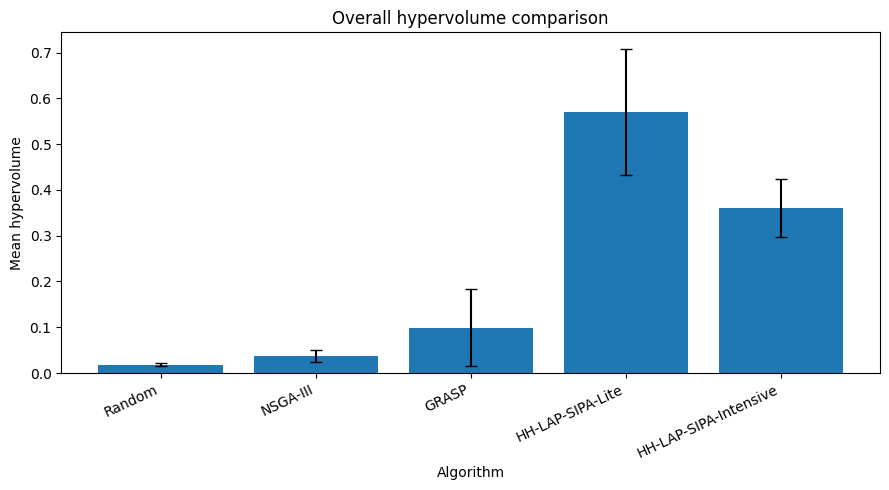

In [18]:
# =========================
# FIGURA 6.1 — MEDIA GLOBAL DE HYPERVOLUME
# =========================

# genera un gráfico de barras con el hypervolume medio global por algoritmo.

plot_df = overall_hv.copy()
plot_df = plot_df.set_index("algorithm").loc[ALGORITHM_ORDER].reset_index()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_df["algorithm_label"],
    plot_df["mean_hv"],
    yerr=plot_df["ci95_half_width"],
    capsize=4
)

plt.ylabel("Mean hypervolume")
plt.xlabel("Algorithm")
plt.title("Overall hypervolume comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fig_6_1_overall_hypervolume.png", dpi=300)
plt.show()

In [19]:
# OPCIONAL

# =========================
# TEST DE FRIEDMAN
# Comparación global entre algoritmos
# =========================

# Qué hace: aplica Friedman sobre las 20 instancias, usando el hypervolume medio por algoritmo en cada instancia. Esto puede servir como respaldo estadístico, aunque no es obligatorio meterlo todo en el paper.

friedman_data = [
    pivot_instance[alg].values
    for alg in ALGORITHM_ORDER
]

friedman_stat, friedman_p = stats.friedmanchisquare(*friedman_data)

friedman_result = pd.DataFrame([{
    "test": "Friedman",
    "n_instances": pivot_instance.shape[0],
    "statistic": friedman_stat,
    "p_value": friedman_p,
}])

display(friedman_result)

,test,n_instances,statistic,p_value
0,Friedman,20,63.0,6.785896e-13


In [20]:
# OPCIONAL

# =========================
# COMPARACIONES PAREADAS WILCOXON + HOLM
# =========================

# compara algoritmos por pares sobre las mismas 20 instancias. Lo dejaría como material de apoyo, no necesariamente como tabla principal del paper.

pairwise_rows = []

for i, alg_a in enumerate(ALGORITHM_ORDER):
    for alg_b in ALGORITHM_ORDER[i + 1:]:
        x = pivot_instance[alg_a].values
        y = pivot_instance[alg_b].values

        stat, p = stats.wilcoxon(
            x,
            y,
            zero_method="wilcox",
            alternative="two-sided"
        )

        diff = x - y

        pairwise_rows.append({
            "algorithm_a": alg_a,
            "algorithm_a_label": ALGORITHM_LABELS[alg_a],
            "algorithm_b": alg_b,
            "algorithm_b_label": ALGORITHM_LABELS[alg_b],
            "mean_diff_a_minus_b": np.mean(diff),
            "median_diff_a_minus_b": np.median(diff),
            "wilcoxon_statistic": stat,
            "p_value": p,
        })

pairwise = (
    pd.DataFrame(pairwise_rows)
    .sort_values("p_value")
    .reset_index(drop=True)
)

# Corrección de Holm
m = len(pairwise)
adjusted = []

for rank, p in enumerate(pairwise["p_value"], start=1):
    adjusted.append(min((m - rank + 1) * p, 1.0))

# Asegurar monotonía
for i in range(1, len(adjusted)):
    adjusted[i] = max(adjusted[i], adjusted[i - 1])

pairwise["holm_adjusted_p"] = adjusted
pairwise["significant_0_05"] = pairwise["holm_adjusted_p"] < 0.05

display(pairwise)

,algorithm_a,algorithm_a_label,algorithm_b,algorithm_b_label,mean_diff_a_minus_b,median_diff_a_minus_b,wilcoxon_statistic,p_value,holm_adjusted_p,significant_0_05
0,random,Random,nsga3,NSGA-III,-0.018883,-0.011300,0.0,0.000002,0.000019,True
1,random,Random,hh_lap_v0,HH-LAP-SIPA-Lite,-0.552714,-0.705086,0.0,0.000002,0.000019,True
2,random,Random,hh_lap_v1,HH-LAP-SIPA-Intensive,-0.342520,-0.299263,0.0,0.000002,0.000019,True
3,nsga3,NSGA-III,hh_lap_v1,HH-LAP-SIPA-Intensive,-0.323637,-0.286673,0.0,0.000002,0.000019,True
4,grasp,GRASP,hh_lap_v1,HH-LAP-SIPA-Intensive,-0.261724,-0.282203,3.0,0.000010,0.000057,True
5,nsga3,NSGA-III,hh_lap_v0,HH-LAP-SIPA-Lite,-0.533831,-0.688420,4.0,0.000013,0.000067,True
6,grasp,GRASP,hh_lap_v0,HH-LAP-SIPA-Lite,-0.471918,-0.662857,8.0,0.000048,0.000191,True
7,hh_lap_v0,HH-LAP-SIPA-Lite,hh_lap_v1,HH-LAP-SIPA-Intensive,0.210194,0.387237,47.0,0.029575,0.088726,False
8,nsga3,NSGA-III,grasp,GRASP,-0.061913,0.011203,74.0,0.261099,0.522198,False
9,random,Random,grasp,GRASP,-0.080795,0.003069,74.0,0.261099,0.522198,False


## Hypervolume by instance size

In [ ]:
# =========================
# HYPERVOLUME POR TAMAÑO DE INSTANCIA
# =========================

hv_by_size = (
    hv_summary
    .groupby(["n_students", "algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .agg(
        n_instances="count",
        mean_hv="mean",
        std_hv="std",
        median_hv="median",
        min_hv="min",
        max_hv="max"
    )
    .reset_index()
)

hv_by_size["ci95_half_width"] = (
    hv_summary
    .groupby(["n_students", "algorithm", "algorithm_label"], observed=True)["mean_hv"]
    .apply(ci95)
    .reset_index(drop=True)
)

hv_by_size["ci95_low"] = hv_by_size["mean_hv"] - hv_by_size["ci95_half_width"]
hv_by_size["ci95_high"] = hv_by_size["mean_hv"] + hv_by_size["ci95_half_width"]

display(hv_by_size)

In [ ]:
hv_by_size.to_csv(OUTPUT_DIR / "hv_by_instance_size.csv", index=False)

In [ ]:
# =========================
# TABLA PIVOT 6.2
# =========================

# genera una tabla mucho más legible: filas = tamaño, columnas = algoritmo

hv_by_size_pivot = hv_by_size.pivot_table(
    index="n_students",
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)

# Ordenar columnas
hv_by_size_pivot = hv_by_size_pivot[LABEL_ORDER]

display(hv_by_size_pivot)

In [ ]:
hv_by_size_pivot.to_csv(OUTPUT_DIR / "table_6_2_hv_by_size.csv")

In [ ]:
# =========================
# GANADOR POR TAMAÑO
# =========================

winners_by_size = []

for n_students, row in hv_by_size_pivot.iterrows():
    sorted_row = row.sort_values(ascending=False)

    winners_by_size.append({
        "n_students": n_students,
        "best_algorithm_label": sorted_row.index[0],
        "best_mean_hv": sorted_row.iloc[0],
        "second_algorithm_label": sorted_row.index[1],
        "second_mean_hv": sorted_row.iloc[1],
        "gap_best_second": sorted_row.iloc[0] - sorted_row.iloc[1],
    })

winners_by_size = pd.DataFrame(winners_by_size)

display(winners_by_size)

In [ ]:
winners_by_size.to_csv(OUTPUT_DIR / "winners_by_size.csv", index=False)

In [ ]:
# =========================
# RANKING POR TAMAÑO
# =========================

rank_by_size = hv_by_size_pivot.rank(
    axis=1,
    ascending=False,
    method="average"
)

display(rank_by_size)

In [ ]:
rank_by_size.to_csv(OUTPUT_DIR / "rank_by_size.csv")

### Gráficos (hv por tamaño y de ranking)

In [ ]:
# =========================
# FIGURA 6.2 — HYPERVOLUME POR TAMAÑO
# =========================

plt.figure(figsize=(9, 5))

for alg in ALGORITHM_ORDER:
    sub = (
        hv_by_size[hv_by_size["algorithm"] == alg]
        .sort_values("n_students")
    )

    plt.errorbar(
        sub["n_students"],
        sub["mean_hv"],
        yerr=sub["ci95_half_width"],
        marker="o",
        capsize=4,
        label=ALGORITHM_LABELS[alg]
    )

plt.xlabel("Number of students")
plt.ylabel("Mean hypervolume")
plt.title("Hypervolume by instance size")
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fig_6_2_hypervolume_by_size.png", dpi=300)
plt.show()

In [ ]:
# =========================
# FIGURA 6.2 — RANKING POR TAMAÑO
# =========================

rank_by_size_long = (
    rank_by_size
    .reset_index()
    .melt(
        id_vars="n_students",
        var_name="algorithm_label",
        value_name="rank"
    )
)

plt.figure(figsize=(9, 5))

for alg_label in LABEL_ORDER:
    sub = (
        rank_by_size_long[rank_by_size_long["algorithm_label"] == alg_label]
        .sort_values("n_students")
    )

    plt.plot(
        sub["n_students"],
        sub["rank"],
        marker="o",
        label=alg_label
    )

plt.xlabel("Number of students")
plt.ylabel("Average rank within size group")
plt.title("Algorithm ranking by instance size")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fig_6_2_rank_by_size.png", dpi=300)
plt.show()

## Instance-level variability

In [ ]:
# ============================================================
# 6.3 INSTANCE-LEVEL VARIABILITY
# Tabla de hypervolume medio por instancia y algoritmo
# ============================================================

def extract_instance_index(instance_name):
    """
    Extrae el índice final de la instancia.
    Ejemplo: problem_instance_ext_600_2 -> 2
    """
    match = re.search(r"_(\d+)$", str(instance_name))
    if match:
        return int(match.group(1))
    return -1


hv_instance_pivot = hv_summary.pivot_table(
    index=["n_students", "instance_clean"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)

# Ordenar columnas de algoritmos
hv_instance_pivot = hv_instance_pivot[LABEL_ORDER]

# Pasar a tabla normal
hv_instance_table = hv_instance_pivot.reset_index()

# Añadir índice de instancia para ordenar mejor
hv_instance_table["instance_id"] = hv_instance_table["instance_clean"].apply(extract_instance_index)

hv_instance_table = (
    hv_instance_table
    .sort_values(["n_students", "instance_id"])
    .drop(columns=["instance_id"])
)

display(hv_instance_table)

In [ ]:
hv_instance_table.to_csv(
    OUTPUT_DIR / "table_6_3_hv_by_instance_algorithm.csv",
    index=False
)

In [ ]:
# ============================================================
# GANADOR Y SEGUNDO MEJOR POR INSTANCIA
# ============================================================

instance_winner_rows = []

for _, row in hv_instance_table.iterrows():
    n_students = row["n_students"]
    instance_clean = row["instance_clean"]

    hv_values = row[LABEL_ORDER].astype(float).sort_values(ascending=False)

    best_algorithm = hv_values.index[0]
    second_algorithm = hv_values.index[1]

    instance_winner_rows.append({
        "n_students": n_students,
        "instance_clean": instance_clean,
        "best_algorithm": best_algorithm,
        "best_mean_hv": hv_values.iloc[0],
        "second_algorithm": second_algorithm,
        "second_mean_hv": hv_values.iloc[1],
        "gap_best_second": hv_values.iloc[0] - hv_values.iloc[1],
    })

instance_winners_6_3 = pd.DataFrame(instance_winner_rows)

display(instance_winners_6_3)

In [ ]:
instance_winners_6_3.to_csv(
    OUTPUT_DIR / "table_6_3_instance_winners.csv",
    index=False
)

In [ ]:
# ============================================================
# CONTEO DE VICTORIAS POR ALGORITMO
# ============================================================

instance_win_counts_6_3 = (
    instance_winners_6_3
    .groupby("best_algorithm")
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values("n_instance_wins", ascending=False)
)

display(instance_win_counts_6_3)

In [ ]:
# ============================================================
# CONTEO DE VICTORIAS POR TAMAÑO
# ============================================================

instance_win_counts_by_size_6_3 = (
    instance_winners_6_3
    .groupby(["n_students", "best_algorithm"])
    .size()
    .reset_index(name="n_instance_wins")
    .sort_values(["n_students", "n_instance_wins"], ascending=[True, False])
)

display(instance_win_counts_by_size_6_3)

In [ ]:
instance_win_counts_6_3.to_csv(
    OUTPUT_DIR / "table_6_3_instance_win_counts.csv",
    index=False
)

instance_win_counts_by_size_6_3.to_csv(
    OUTPUT_DIR / "table_6_3_instance_win_counts_by_size.csv",
    index=False
)

In [ ]:
# ============================================================
# COMPARACIÓN DIRECTA HH-LAP-SIPA-LITE VS INTENSIVE
# ============================================================

lite_label = "HH-LAP-SIPA-Lite"
intensive_label = "HH-LAP-SIPA-Intensive"

lite_vs_intensive = hv_instance_table[[
    "n_students",
    "instance_clean",
    lite_label,
    intensive_label
]].copy()

lite_vs_intensive["diff_lite_minus_intensive"] = (
    lite_vs_intensive[lite_label] - lite_vs_intensive[intensive_label]
)

lite_vs_intensive["best_variant"] = np.where(
    lite_vs_intensive["diff_lite_minus_intensive"] >= 0,
    lite_label,
    intensive_label
)

lite_vs_intensive["abs_diff"] = lite_vs_intensive["diff_lite_minus_intensive"].abs()

display(lite_vs_intensive)

In [ ]:
lite_vs_intensive_summary = (
    lite_vs_intensive
    .groupby("best_variant")
    .size()
    .reset_index(name="n_instances")
    .sort_values("n_instances", ascending=False)
)

display(lite_vs_intensive_summary)

In [ ]:
lite_vs_intensive.to_csv(
    OUTPUT_DIR / "table_6_3_lite_vs_intensive_by_instance.csv",
    index=False
)

lite_vs_intensive_summary.to_csv(
    OUTPUT_DIR / "table_6_3_lite_vs_intensive_summary.csv",
    index=False
)

### Figuras

In [ ]:
# ============================================================
# FIGURA 6.3 — HYPERVOLUME POR INSTANCIA
# ============================================================

plot_instance_table = hv_instance_table.copy()
plot_instance_table["instance_short"] = (
    plot_instance_table["n_students"].astype(str)
    + "_"
    + plot_instance_table["instance_clean"].apply(extract_instance_index).astype(str)
)

plt.figure(figsize=(12, 5))

for alg_label in LABEL_ORDER:
    plt.plot(
        plot_instance_table["instance_short"],
        plot_instance_table[alg_label],
        marker="o",
        label=alg_label
    )

plt.xlabel("Instance")
plt.ylabel("Mean hypervolume")
plt.title("Mean hypervolume by individual instance")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fig_6_3_hypervolume_by_instance.png", dpi=300)
plt.show()

In [ ]:
# ============================================================
# FIGURA 6.3 — DIFERENCIA LITE - INTENSIVE
# ============================================================

plot_diff = lite_vs_intensive.copy()
plot_diff["instance_short"] = (
    plot_diff["n_students"].astype(str)
    + "_"
    + plot_diff["instance_clean"].apply(extract_instance_index).astype(str)
)

plt.figure(figsize=(12, 5))

plt.bar(
    plot_diff["instance_short"],
    plot_diff["diff_lite_minus_intensive"]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Instance")
plt.ylabel("Hypervolume difference")
plt.title("HH-LAP-SIPA-Lite minus HH-LAP-SIPA-Intensive by instance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fig_6_3_lite_minus_intensive_by_instance.png", dpi=300)
plt.show()

## Per-objective performance analysis

In [ ]:
# ============================================================
# 6.4 PER-OBJECTIVE PERFORMANCE ANALYSIS
# Cargar todos los frentes Pareto
# ============================================================

PARETO_DIR = ROOT / "pareto"

if not PARETO_DIR.exists():
    raise FileNotFoundError(f"No se ha encontrado la carpeta de Pareto: {PARETO_DIR}")

pareto_files = sorted(PARETO_DIR.glob("*.csv"))

print("Número de archivos Pareto encontrados:", len(pareto_files))

expected_pareto_files = 20 * 5 * 30

if len(pareto_files) != expected_pareto_files:
    print(f"WARNING: expected {expected_pareto_files} Pareto files, found {len(pareto_files)}")
else:
    print("Pareto files check OK.")

In [ ]:
# ============================================================
# LECTURA DE PARETO FRONTS
# ============================================================

pareto_dfs = []

required_objective_cols = [
    "tau_sum",
    "eta_sum",
    "lbar_sum",
    "sigma_sum"
]

for file in pareto_files:
    df = pd.read_csv(file)

    missing_cols = [c for c in required_objective_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Faltan columnas {missing_cols} en {file.name}")

    df["source_file"] = file.name
    df["instance_clean"] = df["instance"].apply(normalize_instance_name)
    df["algorithm_label"] = df["algorithm"].map(ALGORITHM_LABELS)

    pareto_dfs.append(df)

pareto_all = pd.concat(pareto_dfs, ignore_index=True)

pareto_all["algorithm"] = pd.Categorical(
    pareto_all["algorithm"],
    categories=ALGORITHM_ORDER,
    ordered=True
)

display(pareto_all.head())
print("Filas totales en Pareto:", len(pareto_all))

In [ ]:
pareto_all.to_csv(
    OUTPUT_DIR / "all_pareto_solutions.csv",
    index=False
)

In [ ]:
# ============================================================
# OBJETIVOS NORMALIZADOS POR ESTUDIANTE
# ============================================================

pareto_all["tau_per_student"] = pareto_all["tau_sum"] / pareto_all["n_students"]
pareto_all["eta_per_student"] = pareto_all["eta_sum"] / pareto_all["n_students"]

display(pareto_all[[
    "algorithm_label",
    "instance_clean",
    "run_id",
    "tau_sum",
    "eta_sum",
    "tau_per_student",
    "eta_per_student",
    "lbar_sum",
    "sigma_sum"
]].head())

In [ ]:
# ============================================================
# MEJOR VALOR POR OBJETIVO EN CADA RUN
# ============================================================

run_objective_summary = (
    pareto_all
    .groupby(
        ["algorithm", "algorithm_label", "instance_clean", "n_students", "run_id"],
        observed=True
    )
    .agg(
        pareto_size=("solution_id", "count"),

        best_tau_sum=("tau_sum", "max"),
        best_eta_sum=("eta_sum", "max"),
        best_lbar_sum=("lbar_sum", "min"),
        best_sigma_sum=("sigma_sum", "min"),

        best_tau_per_student=("tau_per_student", "max"),
        best_eta_per_student=("eta_per_student", "max"),

        mean_tau_sum=("tau_sum", "mean"),
        mean_eta_sum=("eta_sum", "mean"),
        mean_lbar_sum=("lbar_sum", "mean"),
        mean_sigma_sum=("sigma_sum", "mean"),
    )
    .reset_index()
)

display(run_objective_summary.head())

In [ ]:
run_objective_summary.to_csv(
    OUTPUT_DIR / "table_6_4_run_objective_summary.csv",
    index=False
)

In [ ]:
# ============================================================
# RESUMEN POR ALGORITMO-INSTANCIA
# ============================================================

instance_objective_summary = (
    run_objective_summary
    .groupby(
        ["algorithm", "algorithm_label", "instance_clean", "n_students"],
        observed=True
    )
    .agg(
        mean_best_tau_sum=("best_tau_sum", "mean"),
        std_best_tau_sum=("best_tau_sum", "std"),

        mean_best_eta_sum=("best_eta_sum", "mean"),
        std_best_eta_sum=("best_eta_sum", "std"),

        mean_best_lbar_sum=("best_lbar_sum", "mean"),
        std_best_lbar_sum=("best_lbar_sum", "std"),

        mean_best_sigma_sum=("best_sigma_sum", "mean"),
        std_best_sigma_sum=("best_sigma_sum", "std"),

        mean_best_tau_per_student=("best_tau_per_student", "mean"),
        mean_best_eta_per_student=("best_eta_per_student", "mean"),

        mean_pareto_size=("pareto_size", "mean"),
    )
    .reset_index()
)

display(instance_objective_summary.head())

In [ ]:
instance_objective_summary.to_csv(
    OUTPUT_DIR / "table_6_4_instance_objective_summary.csv",
    index=False
)

In [ ]:
# ============================================================
# RESUMEN GLOBAL POR ALGORITMO Y OBJETIVO
# ============================================================

objective_global_summary = (
    instance_objective_summary
    .groupby(["algorithm", "algorithm_label"], observed=True)
    .agg(
        n_instances=("instance_clean", "count"),

        mean_tau_per_student=("mean_best_tau_per_student", "mean"),
        std_tau_per_student=("mean_best_tau_per_student", "std"),

        mean_eta_per_student=("mean_best_eta_per_student", "mean"),
        std_eta_per_student=("mean_best_eta_per_student", "std"),

        mean_lbar_sum=("mean_best_lbar_sum", "mean"),
        std_lbar_sum=("mean_best_lbar_sum", "std"),

        mean_sigma_sum=("mean_best_sigma_sum", "mean"),
        std_sigma_sum=("mean_best_sigma_sum", "std"),

        mean_pareto_size=("mean_pareto_size", "mean"),
    )
    .reset_index()
)

objective_global_summary = objective_global_summary.sort_values("algorithm")

display(objective_global_summary)

In [ ]:
objective_global_summary.to_csv(
    OUTPUT_DIR / "table_6_4_objective_global_summary.csv",
    index=False
)

In [ ]:
# ============================================================
# RANKING MEDIO POR OBJETIVO
# ============================================================

objective_rank_rows = []

objectives_for_ranking = {
    "tau_per_student": {
        "column": "mean_best_tau_per_student",
        "sense": "max"
    },
    "eta_per_student": {
        "column": "mean_best_eta_per_student",
        "sense": "max"
    },
    "lbar_sum": {
        "column": "mean_best_lbar_sum",
        "sense": "min"
    },
    "sigma_sum": {
        "column": "mean_best_sigma_sum",
        "sense": "min"
    },
}

for obj_name, info in objectives_for_ranking.items():
    col = info["column"]
    sense = info["sense"]

    pivot_obj = instance_objective_summary.pivot_table(
        index=["n_students", "instance_clean"],
        columns="algorithm_label",
        values=col,
        observed=True
    )[LABEL_ORDER]

    ranks = pivot_obj.rank(
        axis=1,
        ascending=(sense == "min"),
        method="average"
    )

    avg_rank = ranks.mean(axis=0)

    for alg_label, rank_value in avg_rank.items():
        objective_rank_rows.append({
            "objective": obj_name,
            "algorithm_label": alg_label,
            "average_rank": rank_value,
            "sense": sense
        })

objective_ranks = (
    pd.DataFrame(objective_rank_rows)
    .sort_values(["objective", "average_rank"])
)

display(objective_ranks)

In [ ]:
objective_ranks.to_csv(
    OUTPUT_DIR / "table_6_4_average_rank_by_objective.csv",
    index=False
)

In [ ]:
# ============================================================
# TABLA COMPACTA 6.4
# ============================================================

table_6_4_objectives = objective_global_summary[[
    "algorithm_label",
    "mean_tau_per_student",
    "std_tau_per_student",
    "mean_eta_per_student",
    "std_eta_per_student",
    "mean_lbar_sum",
    "std_lbar_sum",
    "mean_sigma_sum",
    "std_sigma_sum",
    "mean_pareto_size",
]].copy()

table_6_4_objectives = table_6_4_objectives.rename(columns={
    "algorithm_label": "Algorithm",
    "mean_tau_per_student": "Tau/student mean",
    "std_tau_per_student": "Tau/student std",
    "mean_eta_per_student": "Eta/student mean",
    "std_eta_per_student": "Eta/student std",
    "mean_lbar_sum": "Lbar mean",
    "std_lbar_sum": "Lbar std",
    "mean_sigma_sum": "Sigma mean",
    "std_sigma_sum": "Sigma std",
    "mean_pareto_size": "Pareto size mean",
})

display(table_6_4_objectives)

In [ ]:
table_6_4_objectives.to_csv(
    OUTPUT_DIR / "table_6_4_per_objective_summary.csv",
    index=False
)

### Figuras

In [ ]:
# ============================================================
# FIGURAS 6.4 — COMPARACIÓN POR OBJETIVO
# ============================================================

objective_plot_config = [
    {
        "column": "mean_tau_per_student",
        "ylabel": "Best tau per student",
        "title": "Student utility by algorithm",
        "filename": "fig_6_4_tau_per_student_by_algorithm.png"
    },
    {
        "column": "mean_eta_per_student",
        "ylabel": "Best eta per student",
        "title": "Company-side utility by algorithm",
        "filename": "fig_6_4_eta_per_student_by_algorithm.png"
    },
    {
        "column": "mean_lbar_sum",
        "ylabel": "Best lbar_sum",
        "title": "Supervision dispersion by algorithm",
        "filename": "fig_6_4_lbar_by_algorithm.png"
    },
    {
        "column": "mean_sigma_sum",
        "ylabel": "Best sigma_sum",
        "title": "Workload imbalance by algorithm",
        "filename": "fig_6_4_sigma_by_algorithm.png"
    },
]

for cfg in objective_plot_config:
    plot_df = objective_global_summary.set_index("algorithm").loc[ALGORITHM_ORDER].reset_index()

    plt.figure(figsize=(9, 5))

    plt.bar(
        plot_df["algorithm_label"],
        plot_df[cfg["column"]]
    )

    plt.xlabel("Algorithm")
    plt.ylabel(cfg["ylabel"])
    plt.title(cfg["title"])
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    plt.savefig(OUTPUT_DIR / cfg["filename"], dpi=300)
    plt.show()

In [ ]:
# ============================================================
# LITE VS INTENSIVE POR OBJETIVO
# ============================================================

variants_objectives = objective_global_summary[
    objective_global_summary["algorithm_label"].isin([
        "HH-LAP-SIPA-Lite",
        "HH-LAP-SIPA-Intensive"
    ])
].copy()

display(variants_objectives)

In [ ]:
variants_objectives_pivot = variants_objectives.set_index("algorithm_label")[[
    "mean_tau_per_student",
    "mean_eta_per_student",
    "mean_lbar_sum",
    "mean_sigma_sum",
    "mean_pareto_size"
]]

display(variants_objectives_pivot)

In [ ]:
variants_objectives_pivot.to_csv(
    OUTPUT_DIR / "table_6_4_lite_vs_intensive_objectives.csv"
)

## Analysis of HH-LAP-SIPA variants

In [ ]:
# ============================================================
# 6.5 ANALYSIS OF HH-LAP-SIPA VARIANTS
# Configuración
# ============================================================

LITE_LABEL = "HH-LAP-SIPA-Lite"
INTENSIVE_LABEL = "HH-LAP-SIPA-Intensive"

VARIANT_LABELS = [
    LITE_LABEL,
    INTENSIVE_LABEL
]

VARIANT_ALGORITHMS = [
    "hh_lap_v0",
    "hh_lap_v1"
]

In [ ]:
# ============================================================
# HYPERVOLUME LITE VS INTENSIVE POR INSTANCIA
# ============================================================

variant_hv_instance = hv_summary[
    hv_summary["algorithm_label"].isin(VARIANT_LABELS)
].copy()

variant_hv_pivot = variant_hv_instance.pivot_table(
    index=["n_students", "instance_clean"],
    columns="algorithm_label",
    values="mean_hv",
    observed=True
)[VARIANT_LABELS].reset_index()

variant_hv_pivot["diff_lite_minus_intensive"] = (
    variant_hv_pivot[LITE_LABEL] - variant_hv_pivot[INTENSIVE_LABEL]
)

variant_hv_pivot["relative_diff_pct"] = np.where(
    variant_hv_pivot[INTENSIVE_LABEL] != 0,
    100.0 * variant_hv_pivot["diff_lite_minus_intensive"] / variant_hv_pivot[INTENSIVE_LABEL],
    np.nan
)

variant_hv_pivot["best_variant"] = np.where(
    variant_hv_pivot["diff_lite_minus_intensive"] >= 0,
    LITE_LABEL,
    INTENSIVE_LABEL
)

display(variant_hv_pivot)

In [ ]:
variant_hv_pivot.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_hv_by_instance.csv",
    index=False
)

In [ ]:
# ============================================================
# RESUMEN GLOBAL LITE VS INTENSIVE
# ============================================================

variant_hv_global = pd.DataFrame([{
    "n_instances": len(variant_hv_pivot),
    "lite_mean_hv": variant_hv_pivot[LITE_LABEL].mean(),
    "intensive_mean_hv": variant_hv_pivot[INTENSIVE_LABEL].mean(),
    "mean_diff_lite_minus_intensive": variant_hv_pivot["diff_lite_minus_intensive"].mean(),
    "std_diff_lite_minus_intensive": variant_hv_pivot["diff_lite_minus_intensive"].std(),
    "lite_wins": (variant_hv_pivot["best_variant"] == LITE_LABEL).sum(),
    "intensive_wins": (variant_hv_pivot["best_variant"] == INTENSIVE_LABEL).sum(),
    "mean_relative_diff_pct": variant_hv_pivot["relative_diff_pct"].mean(),
}])

display(variant_hv_global)

In [ ]:
# ============================================================
# RESUMEN POR TAMAÑO
# ============================================================

variant_hv_by_size = (
    variant_hv_pivot
    .groupby("n_students")
    .agg(
        n_instances=("instance_clean", "count"),
        lite_mean_hv=(LITE_LABEL, "mean"),
        intensive_mean_hv=(INTENSIVE_LABEL, "mean"),
        mean_diff_lite_minus_intensive=("diff_lite_minus_intensive", "mean"),
        std_diff_lite_minus_intensive=("diff_lite_minus_intensive", "std"),
        mean_relative_diff_pct=("relative_diff_pct", "mean"),
    )
    .reset_index()
)

variant_wins_by_size = pd.crosstab(
    variant_hv_pivot["n_students"],
    variant_hv_pivot["best_variant"]
).reset_index()

for label in VARIANT_LABELS:
    if label not in variant_wins_by_size.columns:
        variant_wins_by_size[label] = 0

variant_hv_by_size = variant_hv_by_size.merge(
    variant_wins_by_size[["n_students"] + VARIANT_LABELS],
    on="n_students",
    how="left"
)

variant_hv_by_size = variant_hv_by_size.rename(columns={
    LITE_LABEL: "lite_wins",
    INTENSIVE_LABEL: "intensive_wins"
})

display(variant_hv_by_size)

In [ ]:
variant_hv_global.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_hv_global.csv",
    index=False
)

variant_hv_by_size.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_hv_by_size.csv",
    index=False
)

In [ ]:
# ============================================================
# TEST PAREADO LITE VS INTENSIVE
# ============================================================

diff_values = variant_hv_pivot["diff_lite_minus_intensive"].dropna()

if len(diff_values) > 0 and not np.allclose(diff_values, 0):
    stat, p_value = stats.wilcoxon(diff_values)
else:
    stat, p_value = np.nan, np.nan

variant_hv_test = pd.DataFrame([{
    "comparison": "HH-LAP-SIPA-Lite vs HH-LAP-SIPA-Intensive",
    "test": "Wilcoxon signed-rank",
    "n_instances": len(diff_values),
    "statistic": stat,
    "p_value": p_value,
    "mean_diff_lite_minus_intensive": diff_values.mean(),
    "median_diff_lite_minus_intensive": diff_values.median(),
}])

display(variant_hv_test)

In [ ]:
variant_hv_test.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_wilcoxon.csv",
    index=False
)

In [ ]:
# ============================================================
# LITE VS INTENSIVE POR OBJETIVO
# ============================================================

objective_variant_config = [
    {
        "objective": "tau_per_student",
        "column": "mean_best_tau_per_student",
        "sense": "max"
    },
    {
        "objective": "eta_per_student",
        "column": "mean_best_eta_per_student",
        "sense": "max"
    },
    {
        "objective": "lbar_sum",
        "column": "mean_best_lbar_sum",
        "sense": "min"
    },
    {
        "objective": "sigma_sum",
        "column": "mean_best_sigma_sum",
        "sense": "min"
    },
]

objective_variant_rows = []

for cfg in objective_variant_config:
    obj = cfg["objective"]
    col = cfg["column"]
    sense = cfg["sense"]

    pivot_obj = instance_objective_summary[
        instance_objective_summary["algorithm_label"].isin(VARIANT_LABELS)
    ].pivot_table(
        index=["n_students", "instance_clean"],
        columns="algorithm_label",
        values=col,
        observed=True
    )[VARIANT_LABELS].reset_index()

    for _, row in pivot_obj.iterrows():
        lite_value = row[LITE_LABEL]
        intensive_value = row[INTENSIVE_LABEL]

        raw_diff = lite_value - intensive_value

        if sense == "max":
            diff_in_preferred_direction = raw_diff
            best_variant = LITE_LABEL if raw_diff >= 0 else INTENSIVE_LABEL
        else:
            diff_in_preferred_direction = intensive_value - lite_value
            best_variant = LITE_LABEL if diff_in_preferred_direction >= 0 else INTENSIVE_LABEL

        objective_variant_rows.append({
            "objective": obj,
            "sense": sense,
            "n_students": row["n_students"],
            "instance_clean": row["instance_clean"],
            "lite_value": lite_value,
            "intensive_value": intensive_value,
            "raw_diff_lite_minus_intensive": raw_diff,
            "diff_in_preferred_direction": diff_in_preferred_direction,
            "best_variant": best_variant,
        })

objective_variant_instance = pd.DataFrame(objective_variant_rows)

display(objective_variant_instance)

In [ ]:
# ============================================================
# RESUMEN LITE VS INTENSIVE POR OBJETIVO
# ============================================================

objective_variant_summary = (
    objective_variant_instance
    .groupby(["objective", "sense"])
    .agg(
        n_instances=("instance_clean", "count"),
        lite_mean=("lite_value", "mean"),
        intensive_mean=("intensive_value", "mean"),
        mean_raw_diff_lite_minus_intensive=("raw_diff_lite_minus_intensive", "mean"),
        mean_diff_in_preferred_direction=("diff_in_preferred_direction", "mean"),
        median_diff_in_preferred_direction=("diff_in_preferred_direction", "median"),
        lite_wins=("best_variant", lambda x: (x == LITE_LABEL).sum()),
        intensive_wins=("best_variant", lambda x: (x == INTENSIVE_LABEL).sum()),
    )
    .reset_index()
)

display(objective_variant_summary)

In [ ]:
objective_variant_instance.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_objectives_by_instance.csv",
    index=False
)

objective_variant_summary.to_csv(
    OUTPUT_DIR / "table_6_5_lite_vs_intensive_objectives_summary.csv",
    index=False
)

### Figuras

In [ ]:
# ============================================================
# FIGURAS 6.5 — DIFERENCIAS POR OBJETIVO
# Valores positivos favorecen a Lite
# ============================================================

def make_instance_short_label(df):
    extracted_id = df["instance_clean"].astype(str).str.extract(r"_(\d+)$")[0]
    extracted_id = extracted_id.fillna(df["instance_clean"].astype(str))

    return df["n_students"].astype(str) + "_" + extracted_id.astype(str)


for cfg in objective_variant_config:
    obj = cfg["objective"]

    plot_df = objective_variant_instance[
        objective_variant_instance["objective"] == obj
    ].copy()

    plot_df["instance_short"] = make_instance_short_label(plot_df)

    plt.figure(figsize=(12, 5))

    plt.bar(
        plot_df["instance_short"],
        plot_df["diff_in_preferred_direction"]
    )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("Instance")
    plt.ylabel("Difference in preferred direction")
    plt.title(f"Lite vs Intensive for {obj}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    filename = f"fig_6_5_lite_vs_intensive_{obj}.png"
    plt.savefig(OUTPUT_DIR / filename, dpi=300)
    plt.show()

In [ ]:
# ============================================================
# COSTE COMPUTACIONAL LITE VS INTENSIVE
# ============================================================

# Preferimos columnas de tiempo real medido, no columnas de presupuesto/límite.
preferred_runtime_cols = [
    "elapsed_seconds",
    "runtime_seconds",
    "wall_time_seconds",
    "duration_seconds",
]

runtime_col = None

for col in preferred_runtime_cols:
    if col in stats_all.columns and pd.api.types.is_numeric_dtype(stats_all[col]):
        runtime_col = col
        break

if runtime_col is None:
    runtime_candidates = []

    for col in stats_all.columns:
        col_lower = col.lower()

        if "limit" in col_lower:
            continue

        if any(keyword in col_lower for keyword in ["runtime", "elapsed", "wall", "seconds", "duration"]):
            if pd.api.types.is_numeric_dtype(stats_all[col]):
                runtime_candidates.append(col)

    print("Columnas candidatas de tiempo:", runtime_candidates)

    if len(runtime_candidates) > 0:
        runtime_col = runtime_candidates[0]

if runtime_col is None:
    print("No se ha encontrado ninguna columna numérica de tiempo real. Se omite el análisis de coste computacional.")
    variant_runtime_global = pd.DataFrame()
    variant_runtime_instance = pd.DataFrame()

else:
    print("Columna de tiempo utilizada:", runtime_col)

    stats_variants = stats_all[
        stats_all["algorithm_label"].isin(VARIANT_LABELS)
    ].copy()

    variant_runtime_instance = (
        stats_variants
        .groupby(["algorithm_label", "n_students", "instance_clean"], observed=True)
        .agg(
            mean_runtime=(runtime_col, "mean"),
            std_runtime=(runtime_col, "std"),
            n_runs=(runtime_col, "count"),
        )
        .reset_index()
    )

    variant_runtime_global = (
        stats_variants
        .groupby("algorithm_label", observed=True)
        .agg(
            mean_runtime=(runtime_col, "mean"),
            std_runtime=(runtime_col, "std"),
            median_runtime=(runtime_col, "median"),
            n_runs=(runtime_col, "count"),
        )
        .reset_index()
    )

    display(variant_runtime_instance)
    display(variant_runtime_global)

    variant_runtime_instance.to_csv(
        OUTPUT_DIR / "table_6_5_lite_vs_intensive_runtime_by_instance.csv",
        index=False
    )

    variant_runtime_global.to_csv(
        OUTPUT_DIR / "table_6_5_lite_vs_intensive_runtime_global.csv",
        index=False
    )

In [ ]:
# ============================================================
# TABLA COMPACTA 6.5
# ============================================================

variant_hv_global_tidy = (
    variant_hv_instance
    .groupby("algorithm_label", observed=True)
    .agg(
        mean_hv=("mean_hv", "mean"),
        std_hv=("mean_hv", "std"),
        n_instances=("instance_clean", "nunique"),
    )
    .reset_index()
)

variant_objective_tidy = objective_global_summary[
    objective_global_summary["algorithm_label"].isin(VARIANT_LABELS)
][[
    "algorithm_label",
    "mean_tau_per_student",
    "mean_eta_per_student",
    "mean_lbar_sum",
    "mean_sigma_sum",
    "mean_pareto_size",
]].copy()

table_6_5_variant_summary = variant_hv_global_tidy.merge(
    variant_objective_tidy,
    on="algorithm_label",
    how="left"
)

if "variant_runtime_global" in globals() and not variant_runtime_global.empty:
    table_6_5_variant_summary = table_6_5_variant_summary.merge(
        variant_runtime_global[[
            "algorithm_label",
            "mean_runtime",
            "std_runtime",
            "median_runtime",
        ]],
        on="algorithm_label",
        how="left"
    )

table_6_5_variant_summary = table_6_5_variant_summary.rename(columns={
    "algorithm_label": "Algorithm",
    "mean_hv": "Mean HV",
    "std_hv": "Std HV",
    "n_instances": "Instances",
    "mean_tau_per_student": "Tau/student",
    "mean_eta_per_student": "Eta/student",
    "mean_lbar_sum": "Lbar",
    "mean_sigma_sum": "Sigma",
    "mean_pareto_size": "Pareto size",
    "mean_runtime": "Mean runtime",
    "std_runtime": "Std runtime",
    "median_runtime": "Median runtime",
})

display(table_6_5_variant_summary)

In [ ]:
table_6_5_variant_summary.to_csv(
    OUTPUT_DIR / "table_6_5_variant_summary.csv",
    index=False
)

## General discussion

In [ ]:
# ============================================================
# 6.6 GENERAL DISCUSSION
# Tabla de hallazgos clave
# ============================================================

# Mejor algoritmo global por hypervolume
overall_hv_for_discussion = (
    hv_summary
    .groupby("algorithm_label", observed=True)
    .agg(
        mean_hv=("mean_hv", "mean"),
        std_hv=("mean_hv", "std"),
        n_instances=("instance_clean", "nunique"),
    )
    .reset_index()
    .sort_values("mean_hv", ascending=False)
)

best_overall_algorithm = overall_hv_for_discussion.iloc[0]["algorithm_label"]
best_overall_hv = overall_hv_for_discussion.iloc[0]["mean_hv"]

# Ganadores por instancia
instance_best_for_discussion = []

for (n_students, instance_clean), group in hv_summary.groupby(
    ["n_students", "instance_clean"],
    observed=True
):
    best_row = group.sort_values("mean_hv", ascending=False).iloc[0]

    instance_best_for_discussion.append({
        "n_students": n_students,
        "instance_clean": instance_clean,
        "best_algorithm": best_row["algorithm_label"],
        "best_hv": best_row["mean_hv"],
    })

instance_best_for_discussion = pd.DataFrame(instance_best_for_discussion)

proposed_wins = instance_best_for_discussion[
    instance_best_for_discussion["best_algorithm"].isin(VARIANT_LABELS)
].shape[0]

baseline_wins = instance_best_for_discussion[
    ~instance_best_for_discussion["best_algorithm"].isin(VARIANT_LABELS)
].shape[0]

# Mejor baseline global
baseline_labels = [
    label for label in LABEL_ORDER
    if label not in VARIANT_LABELS
]

best_baseline_row = overall_hv_for_discussion[
    overall_hv_for_discussion["algorithm_label"].isin(baseline_labels)
].iloc[0]

best_baseline_algorithm = best_baseline_row["algorithm_label"]
best_baseline_hv = best_baseline_row["mean_hv"]

# Mejor algoritmo por objetivo usando las columnas globales correctas
objective_discussion_config = [
    {
        "objective": "tau_per_student",
        "column": "mean_tau_per_student",
        "sense": "max"
    },
    {
        "objective": "eta_per_student",
        "column": "mean_eta_per_student",
        "sense": "max"
    },
    {
        "objective": "lbar_sum",
        "column": "mean_lbar_sum",
        "sense": "min"
    },
    {
        "objective": "sigma_sum",
        "column": "mean_sigma_sum",
        "sense": "min"
    },
]

objective_winners_for_discussion = []

for cfg in objective_discussion_config:
    obj = cfg["objective"]
    col = cfg["column"]
    sense = cfg["sense"]

    if sense == "max":
        best_row = objective_global_summary.sort_values(col, ascending=False).iloc[0]
    else:
        best_row = objective_global_summary.sort_values(col, ascending=True).iloc[0]

    objective_winners_for_discussion.append({
        "objective": obj,
        "sense": sense,
        "best_algorithm": best_row["algorithm_label"],
        "best_value": best_row[col],
    })

objective_winners_for_discussion = pd.DataFrame(objective_winners_for_discussion)

discussion_key_findings = pd.DataFrame([
    {
        "finding": "Total algorithms compared",
        "value": hv_summary["algorithm_label"].nunique()
    },
    {
        "finding": "Total instances analyzed",
        "value": hv_summary["instance_clean"].nunique()
    },
    {
        "finding": "Best overall algorithm by mean hypervolume",
        "value": best_overall_algorithm
    },
    {
        "finding": "Best overall mean hypervolume",
        "value": best_overall_hv
    },
    {
        "finding": "Best baseline algorithm by mean hypervolume",
        "value": best_baseline_algorithm
    },
    {
        "finding": "Best baseline mean hypervolume",
        "value": best_baseline_hv
    },
    {
        "finding": "Instances won by proposed HH-LAP-SIPA variants",
        "value": proposed_wins
    },
    {
        "finding": "Instances won by baselines",
        "value": baseline_wins
    },
    {
        "finding": "Lite wins over Intensive",
        "value": int(variant_hv_global["lite_wins"].iloc[0])
    },
    {
        "finding": "Intensive wins over Lite",
        "value": int(variant_hv_global["intensive_wins"].iloc[0])
    },
])

display(discussion_key_findings)
display(objective_winners_for_discussion)

In [ ]:
discussion_key_findings.to_csv(
    OUTPUT_DIR / "table_6_6_discussion_key_findings.csv",
    index=False
)

objective_winners_for_discussion.to_csv(
    OUTPUT_DIR / "table_6_6_objective_winners.csv",
    index=False
)

In [ ]:
# ============================================================
# TABLA FINAL DE RANKING GLOBAL
# ============================================================

final_ranking_table = overall_hv_for_discussion.copy()

final_ranking_table["rank"] = final_ranking_table["mean_hv"].rank(
    ascending=False,
    method="min"
).astype(int)

final_ranking_table = final_ranking_table[[
    "rank",
    "algorithm_label",
    "mean_hv",
    "std_hv",
    "n_instances",
]].sort_values("rank")

final_ranking_table = final_ranking_table.rename(columns={
    "rank": "Rank",
    "algorithm_label": "Algorithm",
    "mean_hv": "Mean HV",
    "std_hv": "Std HV",
    "n_instances": "Instances",
})

display(final_ranking_table)

In [ ]:
final_ranking_table.to_csv(
    OUTPUT_DIR / "table_6_6_final_global_ranking.csv",
    index=False
)

In [ ]:
# ============================================================
# LISTADO FINAL DE ARCHIVOS GENERADOS
# ============================================================

generated_files = sorted(OUTPUT_DIR.glob("*"))

generated_files_df = pd.DataFrame({
    "file": [file.name for file in generated_files],
    "path": [str(file) for file in generated_files],
    "suffix": [file.suffix for file in generated_files],
})

display(generated_files_df)

In [ ]:
generated_files_df.to_csv(
    OUTPUT_DIR / "generated_analysis_files.csv",
    index=False
)